# OSM floorplan decomposition pipeline

**Objective**
Load the cleaned OSM working subset exported by the preprocessing notebook and split every footprint into perimeter zones and core with the corner-ray perimeter, then decompose the zones that are not convex and collect diagnostics.

**Source credit**
The input footprints are derived from OpenStreetMap contributors data and redistributed here in anonymized reduced form under ODbL 1.0. `ConvexDecomp` contributes the workflow and decomposition code, not the underlying source dataset.

**Inputs**
- `data/osm/subset_buildings_gdf.pkl` produced by `OSM_1_Preprocessing.ipynb`

**Workflow overview**
1. Load the preprocessed OSM decomposition working set.
2. Split each footprint into perimeter zones along the facades and core parts with the corner-ray perimeter (`convexdecomp.corner_perimeter`).
3. Run the shared convex decomposition on every zone and collect case-level diagnostics.
4. Inspect representative successful and failed outcomes across the footprint-complexity range.


### Configure notebook environment
Set project paths, choose the footprint set with `OSM_DATASET` (the same set `OSM_1_Preprocessing.ipynb` prepared), and import the reusable OSM helpers used by the decomposition workflow.


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
from IPython import get_ipython

from shapely.geometry import MultiPolygon, Polygon
from shapely.geometry.base import BaseGeometry

ip = get_ipython()
# OSM benefits from widget plots when ipympl is available.
if ip is not None:
    try:
        ip.run_line_magic('matplotlib', 'widget')
    except Exception:
        ip.run_line_magic('matplotlib', 'inline')

# This checkout's src/ goes first on the path, before anything from convexdecomp is imported,
# so that a worktree never runs the code of another checkout.
_checkout = next(path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (path / 'src' / 'convexdecomp').is_dir())
if str(_checkout / 'src') not in sys.path:
    sys.path.insert(0, str(_checkout / 'src'))

from convexdecomp.notebook_utils import find_project_root

PROJECT_ROOT = find_project_root(Path.cwd().resolve())

# 'paper': the bundled OSM set; 'bem4ai_sample': the BEM4AI footprint sample (local only).
OSM_DATASET = 'bem4ai_sample'
OSM_DATA_DIR = {'paper': PROJECT_ROOT / 'data' / 'osm', 'bem4ai_sample': PROJECT_ROOT / 'data' / 'bem4ai'}[OSM_DATASET]
SUBSET_BUILDINGS_PATH = OSM_DATA_DIR / 'subset_buildings_gdf.pkl'

from convexdecomp.plotting.geometry_grid import GHSL_gridplot
from convexdecomp.plotting.polygons import fill_polygon_geometry, set_geometry_frame
from convexdecomp.core.search import AdaptiveSearchConfig
from convexdecomp.osm.decompose import ConvexDecompositionConfig
from convexdecomp.osm.diagnostics import (
    annotate_polygon_failure_reasons,
    parts_from_geom,
    prepare_decomposition_inputs,
    run_building_decomposition,
    select_complexity_ids,
    summarize_building_decomposition,
)
from convexdecomp.corner_perimeter import CornerRayConfig
from convexdecomp.osm.perimeter_zones import build_corner_perimeter_for_gdf, summarize_corner_perimeter

plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['axes.titlesize'] = 10


### Load the preprocessed OSM subset and inspect input diagnostics

**Inputs**
- `subset_buildings_gdf.pkl` of the chosen set (`data/osm/` or `data/bem4ai/`) from `OSM_1_Preprocessing.ipynb`
- Shared helper `convexdecomp.diagnostics.datasets`

**Steps**
1. Load the OSM working subset used by the rest of the notebook.
2. Report how many input polygons the subset contains and how many are already concave.
3. Count how many samples contain at least one polygon below `2.0 m^2`.
4. Plot a compact row of input-distribution diagnostics before perimeter preprocessing and convex decomposition.

**Outputs**
- `subset_buildings_gdf`
- Printed input-dataset diagnostics and a diagnostic plot row

subset_buildings_gdf shape: (990, 5)
columns: ['sample_id', 'geometry', 'area_m2', 'n_vertices', 'n_holes']

=== OSM input diagnostics ===
Samples in working set: 990
Polygons across all samples: 990
Concave polygons before convex decomposition: 601 / 990 (60.7%)
Samples with at least one polygon below 2.0 m^2: 0 / 990 (0.0%)


,sample_id,geometry,area_m2,n_vertices,n_holes
0,A_Coruna_0036,"POLYGON ((11.96383 3.63145, -12.19673 2.86413,...",156.970021,4,0
1,Aachen_0004,"POLYGON ((1.23564 8.40809, -7.6655 1.56753, -3...",130.303791,5,0
2,Aachen_0019,"POLYGON ((-7.05129 -4.87278, 5.74893 -6.42113,...",146.755879,4,0
3,Aachen_0021,"POLYGON ((-16.04263 -9.90517, 18.2648 -4.1635,...",509.372117,8,0
4,Aarhus_0004,"POLYGON ((-17.44828 4.47556, -15.75443 -8.7152...",445.203242,4,0


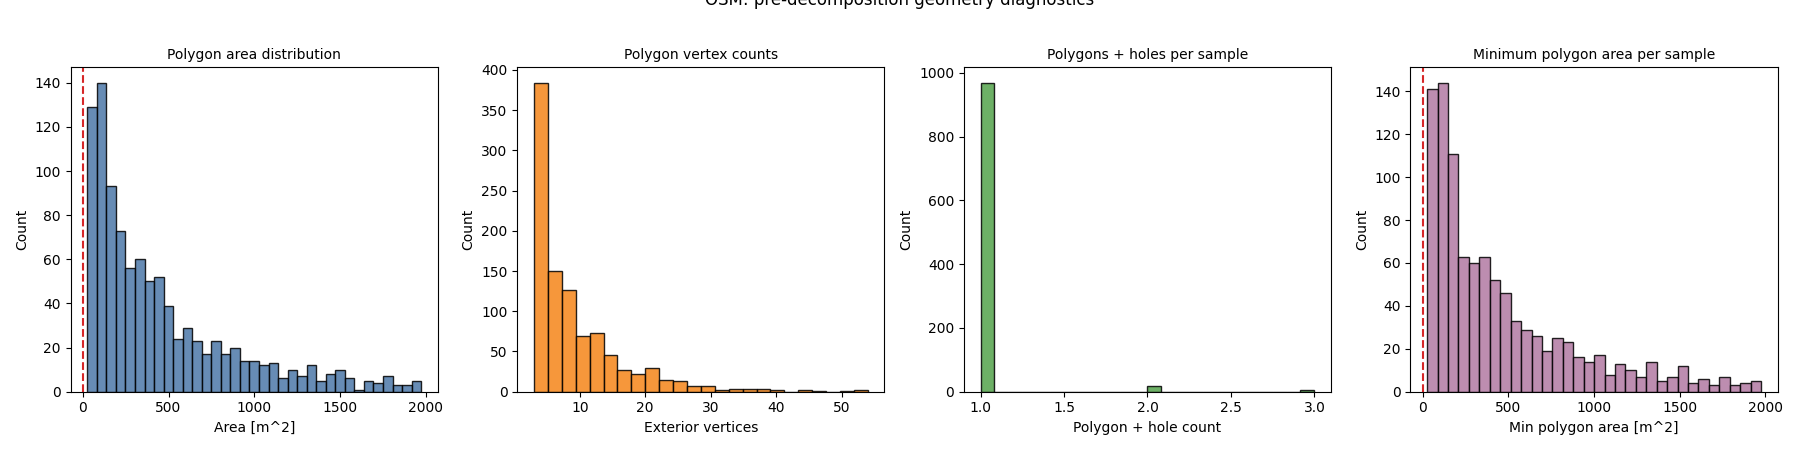

In [2]:
if not SUBSET_BUILDINGS_PATH.exists():
    raise FileNotFoundError(
        f'Missing {SUBSET_BUILDINGS_PATH}. Run OSM_1_Preprocessing.ipynb first to create the preprocessed subset.'
    )

subset_buildings_gdf = pd.read_pickle(SUBSET_BUILDINGS_PATH)

from convexdecomp.diagnostics.datasets import (
    plot_osm_input_dataset_diagnostics,
)

print('subset_buildings_gdf shape:', subset_buildings_gdf.shape)
print('columns:', subset_buildings_gdf.columns.tolist())
print('')
input_diag_summary, input_diag_df = plot_osm_input_dataset_diagnostics(
    subset_buildings_gdf,
    polygons_col='geometry',
    sample_id_col='sample_id',
    min_area_m2=2.0,
    dataset_label='OSM',
)
subset_buildings_gdf.head()


### Configure the corner-ray perimeter
The perimeter zones come from `convexdecomp.corner_perimeter`: a band 4.5 m deep along the facades, rays from the footprint's corners, and ten rules and a tidy step that clean up the zones without ever moving the outline. `CornerRayConfig()` holds the chosen settings; pass a field to change one, for example `CornerRayConfig(band_m=4.0)`. The package README describes every step and setting, and `settings_table()` gives the settings as data.

In [3]:
PERIMETER_CFG = CornerRayConfig()

PERIMETER_CFG

CornerRayConfig(band_m=4.5, tie_m=0.1, min_turn_deg=1.0, wing_end_max_m=4.0, wing_end_parallel_deg=30.0, wing_end_long_sides=False, wing_end_check=True, short_wall_one_ray=True, short_wall_m=1.5, short_wall_chamfers=True, short_wall_midpoint=True, short_wall_to_band=True, short_wall_tooth=True, bays=True, bay_width_band=2.5, bay_depth_band=1.2, bay_edge_deg=45.0, bay_min_corners=2.0, bay_wiggle_deg=5.0, bays_in_band=True, bay_check=True, opposite_gap_m=1.0, opposite_angle_deg=20.0, keep_reflex_rays=True, recast_discarded=False, leg_width_m=2.0, leg_angle_deg=15.0, fill_notches=True, notch_passage_m=1.0, narrow_core_m=1.2, collapse_narrow_parts=True, similar_sides_ratio=0.9, close_points_m=0.5, corner_group_m=1.2, corner_group_span_m=2.0, narrow_zone_m=2.0, min_zone_width_m=2.0, relink_m=4.0, sharp_corner_deg=20.0, sharp_keep_convex=False, repeat_thin_after_sharp=True, hull_keeps_width=True, join_specks=True, speck_m2=0.5, repeat_until_stable=True, snap_to_outline=True, merge_close_agai

### Build the perimeter zones and inspect examples

**Inputs**
- `subset_buildings_gdf` with the working OSM sample in `geometry`
- `PERIMETER_CFG` with the corner-ray perimeter's settings

**Steps**
1. Run the corner-ray perimeter on every building footprint.
2. Store the perimeter zones (`perimeter_parts`, each with its role `perimeter_zone` or `thin_zone` in `perimeter_part_roles`), the core parts (`interior_geom`) and their counts on `subset_buildings_gdf`; a footprint the procedure cannot zone keeps `perimeter_defined = False` and is decomposed whole.
3. Summarize how many buildings have perimeter zones and a core or perimeter zones only, and how many zones are thinner than the zone width or not convex.
4. Plot the outcome counts and the number of perimeter zones per building.
5. Use `GHSL_gridplot` to draw the zones of a few buildings across the range of zone counts: perimeter zones blue, zones thinner than 2 m red, core parts grey.

**Outputs**
- Updated `subset_buildings_gdf` with the perimeter columns
- `perimeter_summary` with building and zone counts
- Gridplots of the zones of example buildings

**Used functions**
`build_corner_perimeter_for_gdf`, `summarize_corner_perimeter`, `GHSL_gridplot`

Corner-ray perimeter summary:
Total buildings: 990
Perimeter zones + core: 626
Perimeter zones only: 364
Perimeter failed (decomposed whole): 0
Perimeter zones: 7338, core parts: 689
Zones thinner than 2 m: 107 in 81 buildings
Zones not convex: 371 in 243 buildings
Time: 43.4 s in total, at most 2.31 s for one building


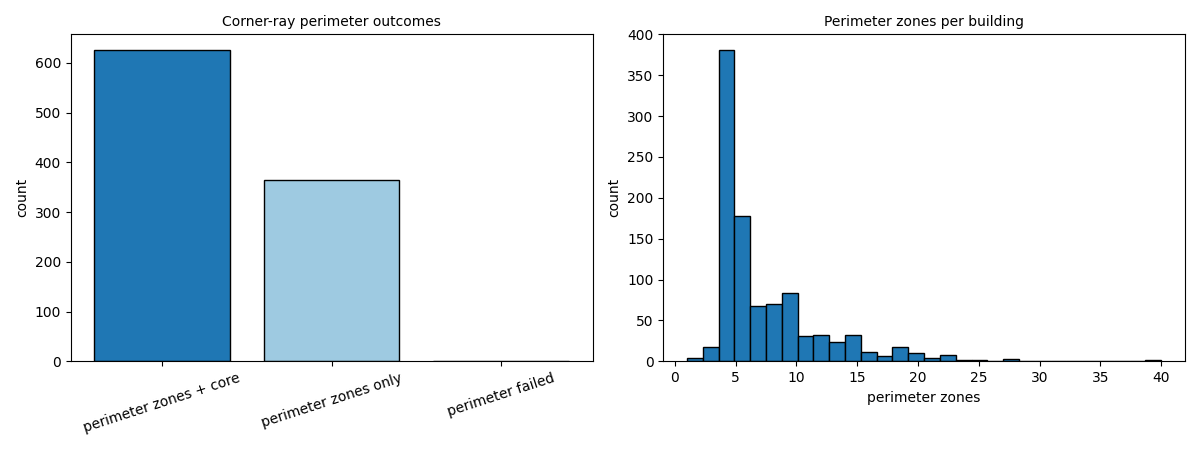

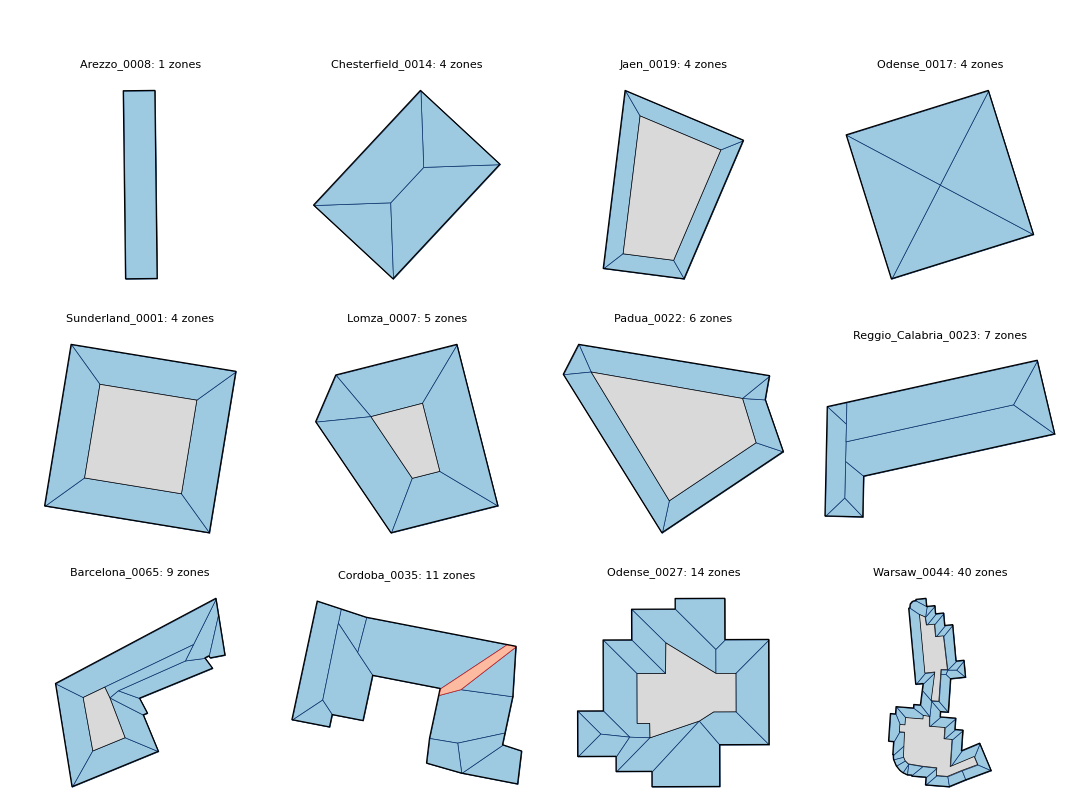

In [4]:
N_SHOW_PERIM = 12

subset_buildings_gdf = build_corner_perimeter_for_gdf(
    subset_buildings_gdf,
    geometry_col='geometry',
    config=PERIMETER_CFG,
)
perimeter_summary = summarize_corner_perimeter(subset_buildings_gdf)

print('Corner-ray perimeter summary:')
print(f"Total buildings: {perimeter_summary['n_total']}")
print(f"Perimeter zones + core: {perimeter_summary['n_with_core']}")
print(f"Perimeter zones only: {perimeter_summary['n_perimeter_only']}")
print(f"Perimeter failed (decomposed whole): {perimeter_summary['n_failed']}")
print(f"Perimeter zones: {perimeter_summary['n_perimeter_zones']}, core parts: {perimeter_summary['n_core_parts']}")
print(
    f"Zones thinner than {PERIMETER_CFG.min_zone_width_m:g} m: {perimeter_summary['n_thin_zones']} "
    f"in {perimeter_summary['n_buildings_with_thin_zones']} buildings"
)
print(
    f"Zones not convex: {perimeter_summary['n_not_convex_zones']} "
    f"in {perimeter_summary['n_buildings_with_not_convex_zones']} buildings"
)
print(
    f"Time: {perimeter_summary['seconds_total']:.1f} s in total, "
    f"at most {perimeter_summary['seconds_max']:.2f} s for one building"
)

outcomes = pd.Series({
    'perimeter zones + core': perimeter_summary['n_with_core'],
    'perimeter zones only': perimeter_summary['n_perimeter_only'],
    'perimeter failed': perimeter_summary['n_failed'],
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(outcomes.index, outcomes.values, color=['#1f77b4', '#9ecae1', '#d9d9d9'], edgecolor='black')
axes[0].set_title('Corner-ray perimeter outcomes')
axes[0].set_ylabel('count')
axes[0].tick_params(axis='x', rotation=18)

axes[1].hist(subset_buildings_gdf['n_perimeter_zones'], bins=30, color='#1f77b4', edgecolor='black')
axes[1].set_title('Perimeter zones per building')
axes[1].set_xlabel('perimeter zones')
axes[1].set_ylabel('count')

plt.tight_layout()
plt.show()

zoned = subset_buildings_gdf.loc[subset_buildings_gdf['perimeter_defined']].sort_values(['n_perimeter_zones', 'sample_id'])
perim_ids = (
    zoned['sample_id'].iloc[np.linspace(0, len(zoned) - 1, min(N_SHOW_PERIM, len(zoned))).astype(int)].tolist()
    if len(zoned) else []
)

if not perim_ids:
    print('No building was zoned by the corner-ray perimeter.')
else:
    bsub = gpd.GeoDataFrame(
        subset_buildings_gdf.loc[subset_buildings_gdf['sample_id'].isin(perim_ids)].copy(),
        geometry='geometry',
        crs=subset_buildings_gdf.crs,
    )
    for role, column in (('perimeter_zone', 'zone_parts'), ('thin_zone', 'thin_parts')):
        bsub[column] = [
            [part for part, r in zip(parts, roles) if r == role]
            for parts, roles in zip(bsub['perimeter_parts'], bsub['perimeter_part_roles'])
        ]
    bsub_core = gpd.GeoDataFrame(
        bsub.loc[bsub['interior_geom'].notna()].copy(),
        geometry='interior_geom',
        crs=subset_buildings_gdf.crs,
    )
    n_zones = bsub.set_index('sample_id')['n_perimeter_zones']

    GHSL_gridplot(
        [
            {
                'name': 'perimeter_zones',
                'gdf': bsub,
                'role': 'main',
                'id_col': 'sample_id',
                'parts_col': 'zone_parts',
                'cmap': ListedColormap(['#9ecae1']),
                'edgecolor': '#08306b',
                'linewidth': 0.5,
                'zorder': 2,
            },
            {
                'name': 'thin_zones',
                'gdf': bsub,
                'role': 'main',
                'id_col': 'sample_id',
                'parts_col': 'thin_parts',
                'cmap': ListedColormap(['#fcbba1']),
                'edgecolor': '#cb181d',
                'linewidth': 0.5,
                'zorder': 2,
            },
            {
                'name': 'core',
                'gdf': bsub_core,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'interior_geom',
                'color': '#d9d9d9',
                'edgecolor': 'black',
                'linewidth': 0.5,
                'zorder': 2,
            },
            {
                'name': 'building_outline',
                'gdf': bsub,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'geometry',
                'color': 'none',
                'edgecolor': 'black',
                'linewidth': 0.9,
                'zorder': 3,
            },
        ],
        ids=perim_ids,
        ncols=4,
        figsize_scale=2.7,
        title_fn=lambda sid, i: f'{sid}: {int(n_zones[sid])} zones',
    )

## Prepare convex decomposition inputs


### Prepare polygon inputs for decomposition

**Inputs**
- `subset_buildings_gdf` with the corner-ray perimeter

**Steps**
1. Build each building's polygon list from its perimeter zones (`perimeter_parts`) and core parts (`interior_geom`), or from the whole footprint where the perimeter failed.
2. Record each polygon's role in `decomp_polygon_roles`: `perimeter_zone`, `thin_zone`, `interior` (a core part) or `footprint`.
3. Store the per-building polygon list in `decomp_polygons` and summarize the polygon and vertex counts.

**Outputs**
- `buildings_convex_gdf` with prepared `decomp_polygons` and `decomp_polygon_roles`

**Used functions**
`prepare_decomposition_inputs`

In [5]:
buildings_convex_gdf, *_ = prepare_decomposition_inputs(
    subset_buildings_gdf,
    use_trapezoid_triangle_precheck=False,  # the trapezoid pre-check belongs to the former offset perimeter
    precheck_subdiv_cfg=None,
)

print('Buildings prepared for decomposition:', len(buildings_convex_gdf))
print('Buildings with perimeter zones + core:', int(buildings_convex_gdf['perimeter'].fillna(False).sum()))
print('Buildings with perimeter zones only:', int(buildings_convex_gdf['perimeter_only'].fillna(False).sum()))
print('Buildings decomposed whole (perimeter failed):', int((~buildings_convex_gdf['perimeter_defined'].fillna(False)).sum()))
print(f"Mean decomposition input polygons per building: {buildings_convex_gdf['n_polygons'].mean():.2f}")
print(f"Mean decomposition input vertices per building: {buildings_convex_gdf['n_vertices'].mean():.2f}")
print('')
print('Decomposition input polygons by role:')
print(buildings_convex_gdf['decomp_polygon_roles'].explode().value_counts().to_string())

Buildings prepared for decomposition: 990
Buildings with perimeter zones + core: 626
Buildings with perimeter zones only: 364
Buildings decomposed whole (perimeter failed): 0
Mean decomposition input polygons per building: 8.11
Mean decomposition input vertices per building: 36.45

Decomposition input polygons by role:
decomp_polygon_roles
perimeter_zone    7231
interior           689
thin_zone          107


### Configure the convex decomposer
Set the polygon-wise decomposer parameters and adaptive retry schedule used on the prepared decomposition inputs. A convex zone comes back as one part. The decomposer's zone rules keep their defaults (`min_zone_width_m` 2 m, `min_corner_deg` 30°): a perimeter zone thinner than 2 m is reported as failed (`thinner_than_min_zone_width`), and a zone that cannot be cut into parts that wide fails too.


In [6]:
cfg = ConvexDecompositionConfig(
    search_depth=24,
    search_width=4,
    max_reflex_per_node=8,
    max_variants_per_polygon=32,
    max_failed_states=500,
    track_time=True,
    min_area_m2=2.0,
    weight_parts=1.0,
    weight_compactness=20.0,
    adaptive_search=AdaptiveSearchConfig(
        enabled=True,
        initial_depth=4,
        initial_width=3,
        max_depth=24,
        max_width=4,
        depth_step=1,
        width_step=1,
    ),
)

cfg


ConvexDecompositionConfig(search_depth=24, search_width=4, max_variants_per_polygon=32, max_failed_states=500, min_area_m2=2.0, weight_parts=1.0, weight_compactness=20.0, area_weighting=0.0, beam_area_weighting=1.0, weight_narrow=0.0, narrow_width_m=2.0, min_concavity_deg=2.0, max_reflex_per_node=8, track_time=True, use_bisector_dead_end_fallback=True, cut_snap_vertex_tolerance_m=0.1, adaptive_search=AdaptiveSearchConfig(enabled=True, initial_depth=4, initial_width=3, max_depth=24, max_width=4, depth_step=1, width_step=1), score_fn=None, beam_ranking='score_first', bisector_always=True, min_corner_deg=30.0, min_zone_width_m=2.0)

## Run convex decomposition

**Inputs**
- `buildings_convex_gdf` with `decomp_polygons`, `n_polygons`, and `n_vertices`
- `cfg` with the convex decomposition search depth, width, adaptive retry schedule, and scoring weights

**Steps**
1. Read the prepared polygon list for each building from `decomp_polygons`.
2. Run `decompose_polygon_with_stats` on each polygon, starting from a cheap search setting and retrying with larger depth, then width, until the first successful parameter setting is found.
3. Collect the returned convex pieces, timings, retry diagnostics, and success flags back to building level.
4. Store the merged convex output geometry in `convex_parts_geom` for later summaries and plots.

**Outputs**
- `buildings_convex_gdf` enriched with per-building convex decomposition results
- `results_df` with counts, flags, timings, retry diagnostics, and output geometries

**Used functions**
`decompose_polygon_with_stats`


In [7]:
buildings_convex_gdf, results_df, polygon_results_gdf = run_building_decomposition(buildings_convex_gdf, cfg)
buildings_convex_gdf.head()


,sample_id,geometry,area_m2,n_vertices,n_holes,perimeter_defined,perimeter,perimeter_only,perimeter_reason,perimeter_parts,...,polygon_search_depths_used,polygon_search_widths_used,polygon_search_attempt_counts,n_failed_polygons,n_small_zone_polygons,n_retried_polygons,total_search_attempts,max_search_depth_used,max_search_width_used,time_total_seconds
0,A_Coruna_0036,"POLYGON ((11.96383 3.63145, -12.19673 2.86413,...",156.970021,14,0,True,False,True,perimeter_only_no_core,[POLYGON ((-12.196733482309734 2.8641335072466...,...,"[None, None, None, None]","[None, None, None, None]","[0, 0, 0, 0]",0,0,0,0,0,0,0.000986
1,Aachen_0004,"POLYGON ((1.23564 8.40809, -7.6655 1.56753, -3...",130.303791,25,0,True,True,False,perimeter_with_core,[POLYGON ((-7.665497909685544 1.56753368733669...,...,"[None, 24, None, None, None, None]","[None, 4, None, None, None, None]","[0, 1, 0, 0, 0, 0]",1,0,0,1,24,4,0.002225
2,Aachen_0019,"POLYGON ((-7.05129 -4.87278, 5.74893 -6.42113,...",146.755879,20,0,True,True,False,perimeter_with_core,[POLYGON ((5.7489268330368795 -6.4211285513452...,...,"[None, None, None, None, None]","[None, None, None, None, None]","[0, 0, 0, 0, 0]",0,0,0,0,0,0,0.000639
3,Aachen_0021,"POLYGON ((-16.04263 -9.90517, 18.2648 -4.1635,...",509.372117,36,0,True,True,False,perimeter_with_core,[POLYGON ((18.26480148505534 -4.16350070489572...,...,"[None, None, None, None, None, None, 4]","[None, None, None, None, None, None, 3]","[0, 0, 0, 0, 0, 0, 1]",0,0,0,1,4,3,0.010627
4,Aarhus_0004,"POLYGON ((-17.44828 4.47556, -15.75443 -8.7152...",445.203242,20,0,True,True,False,perimeter_with_core,[POLYGON ((-15.754426551575293 -8.715258532669...,...,"[None, None, None, None, None]","[None, None, None, None, None]","[0, 0, 0, 0, 0]",0,0,0,0,0,0,0.000637


### Check that no area went missing

Every stage after preprocessing must hand on the footprint's full area: the perimeter band and core, the polygons handed to the decomposer, and the convex parts. Each building carries one error per stage (`perimeter_area_error_m2`, `inputs_area_error_m2`, `parts_area_error_m2`, all against the footprint), and the check stops the notebook if any of them exceeds a millionth of the footprint area. A failed decomposition is not a violation: it has no parts to check.

**Inputs**
- `buildings_convex_gdf` from the decomposition run

**Outputs**
- nothing new; the notebook stops here if a building changed area

**Used functions**
`check_area_conservation`

In [8]:
from convexdecomp.osm.diagnostics import check_area_conservation

check_area_conservation(buildings_convex_gdf)

n_checked = int(buildings_convex_gdf['building_fully_convex'].fillna(False).sum())
largest = buildings_convex_gdf['parts_area_error_m2'].abs().max()
print(f'Area kept at every stage for all {n_checked} fully convex buildings (largest error {largest:.1e} m^2).')

Area kept at every stage for all 754 fully convex buildings (largest error 9.1e-13 m^2).


## Summarize decomposition results

**Inputs**
- `buildings_convex_gdf` with per-building convex decomposition results and adaptive-search diagnostics

**Steps**
1. Count how many individual polygons across all buildings reached a fully convex best variant.
2. Count how many whole buildings have every polygon fully convex.
3. Report the share of buildings that contain any convex part smaller than `cfg.min_area_m2`.
4. Summarize the typical number of convex parts, retry attempts, selected search depths, and runtime per building.

**Outputs**
- Printed convex decomposition summary for the current OSM working set


In [9]:
summary = summarize_building_decomposition(buildings_convex_gdf, min_area_m2=cfg.min_area_m2)

print('=== Convex decomposition summary ===')
print(f"Buildings in working set: {int(summary['n_buildings_total'])}")
print(f"Polygons across all buildings: {int(summary['n_polygons_total'])}")
print(f"Polygons with fully convex decomposition: {int(summary['n_polygons_success'])} ({100.0 * int(summary['n_polygons_success']) / max(int(summary['n_polygons_total']), 1):.1f}%)")
print(f"Buildings with all polygons fully convex: {int(summary['n_buildings_success'])} ({100.0 * int(summary['n_buildings_success']) / max(int(summary['n_buildings_total']), 1):.1f}%)")
print(f"Buildings with at least one failed polygon decomposition: {int(summary['n_buildings_failed'])} ({100.0 * int(summary['n_buildings_failed']) / max(int(summary['n_buildings_total']), 1):.1f}%)")
print(f"Buildings with any zone smaller than {cfg.min_area_m2:.1f} m²: {int(summary['n_small_zone'])} ({100.0 * int(summary['n_small_zone']) / max(int(summary['n_buildings_total']), 1):.1f}%)")
print(f"Polygons that needed at least one retry: {int(summary['n_polygons_retried'])} ({100.0 * int(summary['n_polygons_retried']) / max(int(summary['n_polygons_total']), 1):.1f}%)")
print(f"Mean convex parts per building: {float(summary['parts_per_building_mean']):.2f}")
print(f"Median convex parts per building: {float(summary['parts_per_building_median']):.2f}")
print(f"Mean search attempts per polygon: {float(summary['mean_attempts_per_polygon']):.2f}")
print(f"Max selected search depth: {int(summary['max_search_depth_used'])}")
print(f"Max selected search width: {int(summary['max_search_width_used'])}")
print(f"Mean decomposition time per building: {float(summary['mean_time_seconds']):.4f} s")


=== Convex decomposition summary ===
Buildings in working set: 990
Polygons across all buildings: 8027
Polygons with fully convex decomposition: 7694 (95.9%)
Buildings with all polygons fully convex: 754 (76.2%)
Buildings with at least one failed polygon decomposition: 236 (23.8%)
Buildings with any zone smaller than 2.0 m²: 0 (0.0%)
Polygons that needed at least one retry: 73 (0.9%)
Mean convex parts per building: 8.61
Median convex parts per building: 6.00
Mean search attempts per polygon: 0.14
Max selected search depth: 24
Max selected search width: 25
Mean decomposition time per building: 0.0176 s


## Diagnose failures and small-zone cases


### Summarize polygon-level failure reasons, fallbacks, and retry usage

**Inputs**
- `polygon_results_gdf` with per-polygon decomposition diagnostics
- `cfg.min_area_m2` as the small-zone threshold

**Steps**
1. Classify failed polygons into broad failure modes using the dead-end counters.
2. Count how often each fallback path and retry depth/width setting was used.
3. Print the most common failed polygons and the most common small-zone polygons.
4. Print a focused record for `Ourense_687405085` when it appears in the working set.

**Outputs**
- `failed_polygon_gdf` and `small_zone_polygon_gdf`
- Printed counts for failure reasons, stop reasons, fallback usage, and adaptive retry tiers


In [10]:
polygon_results_gdf, failed_polygon_gdf, small_zone_polygon_gdf = annotate_polygon_failure_reasons(polygon_results_gdf)

print('=== Polygon-level decomposition diagnostics ===')
print(f'Total polygons: {len(polygon_results_gdf)}')
print(f'Failed polygons: {len(failed_polygon_gdf)}')
print(f'Small-zone polygons: {len(small_zone_polygon_gdf)}')
print('')
print('Fallback usage:')
print(polygon_results_gdf['fallback_used'].fillna('none').value_counts().to_string())
print('')
print('Adaptive search attempts per polygon:')
print(polygon_results_gdf['search_attempt_count'].fillna(0).astype(int).value_counts().sort_index().to_string())
print('')
print('Selected search depths:')
used_depths = polygon_results_gdf['search_depth_used'].dropna()
print(used_depths.astype(int).value_counts().sort_index().to_string() if not used_depths.empty else 'None')
print('')
print('Selected search widths:')
used_widths = polygon_results_gdf['search_width_used'].dropna()
print(used_widths.astype(int).value_counts().sort_index().to_string() if not used_widths.empty else 'None')
print('')
print('Failure reasons:')
print(failed_polygon_gdf['failure_reason'].value_counts().to_string() if not failed_polygon_gdf.empty else 'None')
print('')
print('Search stop reasons for failed polygons:')
print(failed_polygon_gdf['search_terminated_by'].fillna('missing').value_counts().to_string() if not failed_polygon_gdf.empty else 'None')
print('')
print('Most common failed polygons:')
print(failed_polygon_gdf['sample_id'].value_counts().head(10).to_string() if not failed_polygon_gdf.empty else 'None')
print('')
print('Most common small-zone polygons:')
print(small_zone_polygon_gdf['sample_id'].value_counts().head(10).to_string() if not small_zone_polygon_gdf.empty else 'None')
print('')

ourense_df = polygon_results_gdf.loc[polygon_results_gdf['sample_id'] == 'Ourense_687405085'].copy()
if ourense_df.empty:
    print('Ourense_687405085 is not present in the current working set.')
else:
    print('Ourense_687405085 diagnostics:')
    print(
        ourense_df[
            [
                'polygon_idx',
                'fully_convex_best',
                'has_small_zone',
                'n_variants',
                'n_parts',
                'best_min_part_area_m2',
                'search_depth_used',
                'search_width_used',
                'search_attempt_count',
                'fallback_used',
                'failure_reason',
                'search_terminated_by',
            ]
        ].to_string(index=False)
    )


=== Polygon-level decomposition diagnostics ===
Total polygons: 8027
Failed polygons: 333
Small-zone polygons: 0

Fallback usage:
fallback_used
none                  8016
sharp_corner             8
diagonal_no_reflex       3

Adaptive search attempts per polygon:
search_attempt_count
0     7186
1      768
2       32
3       14
4        8
5        4
6        3
7        1
8        2
9        3
14       1
15       1
16       2
25       1
27       1

Selected search depths:
search_depth_used
4     656
5      10
6       5
7       2
8       3
9       1
24    164

Selected search widths:
search_width_used
3     677
4     135
5       8
6       7
7       1
8       3
10      2
11      3
15      1
17      1
18      1
24      1
25      1

Failure reasons:
failure_reason
thinner_than_min_zone_width                         173
queue_exhausted                                     133
min_area_dead_ends                                   18
no_reflex_dead_ends                                   6
search_

### Plot representative failed and small-zone polygons
This plot overlays the building outline with the problematic polygon and, for small-zone cases, colors the accepted convex parts to highlight the tiny zones below `cfg.min_area_m2`.


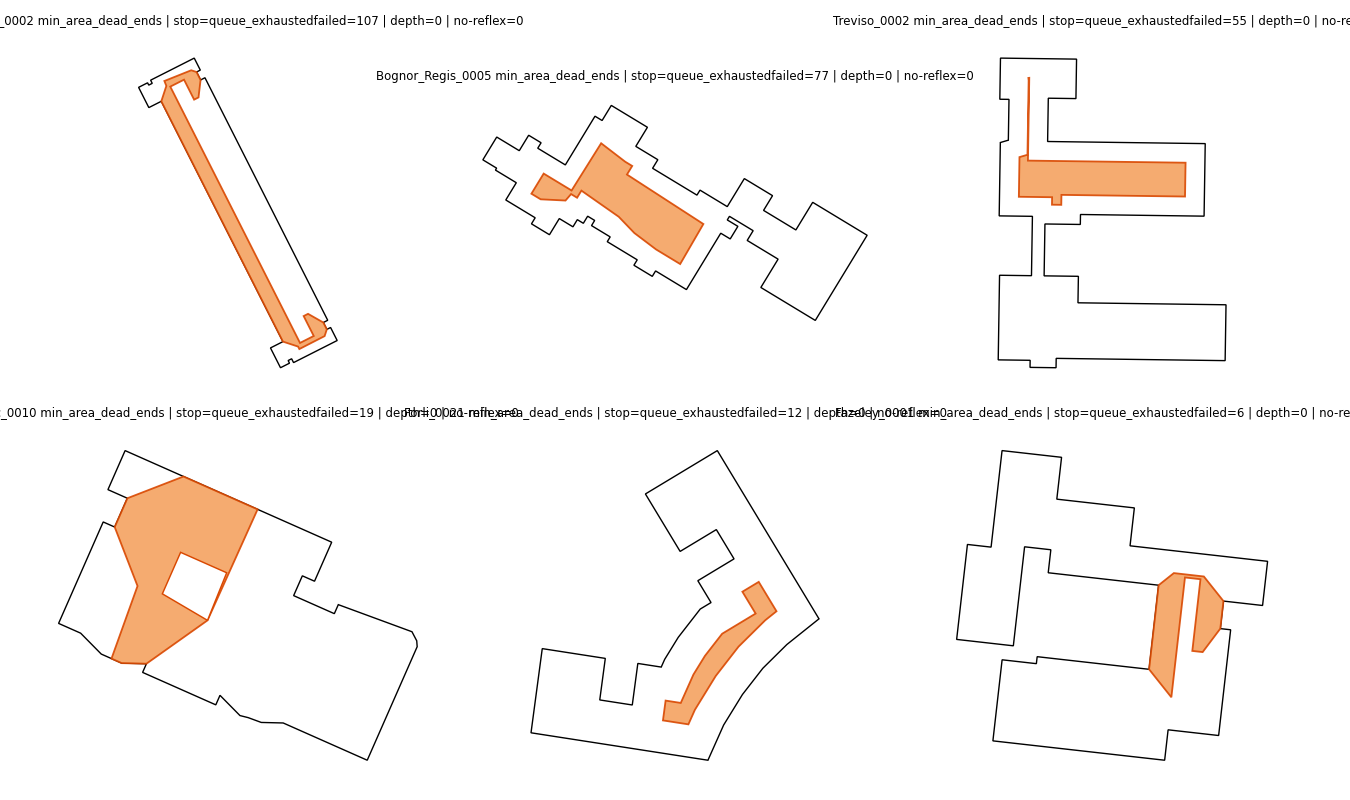

No small-zone polygons under the current configuration.


In [11]:
N_FAILURE_EXAMPLES = 6
N_SMALL_ZONE_EXAMPLES = 6

failed_examples = failed_polygon_gdf.sort_values(
    ['failure_reason', 'n_failed_terminal_states', 'n_states_seen'],
    ascending=[True, False, False],
).head(N_FAILURE_EXAMPLES)
small_zone_examples = small_zone_polygon_gdf.sort_values(
    ['best_min_part_area_m2', 'n_states_seen'],
    ascending=[True, False],
).head(N_SMALL_ZONE_EXAMPLES)

if failed_examples.empty:
    print('No failed polygons under the current configuration.')
else:
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8))
    axes = axes.flatten()
    for ax, (_, rec) in zip(axes, failed_examples.iterrows()):
        fill_polygon_geometry(ax, rec['building_geometry'], facecolor='none', edgecolor='black', linewidth=1.0)
        fill_polygon_geometry(ax, rec['geometry'], facecolor='#f4a261', edgecolor='#d94801', linewidth=1.3, alpha=0.9)
        set_geometry_frame(ax, rec['building_geometry'], min_pad=1.0, pad_ratio=0.08, hide_ticks=True)
        ax.set_title(
            f"{rec['sample_id']} {rec['failure_reason']} | stop={rec['search_terminated_by']}"
            f"failed={int(rec['n_failed_terminal_states'])} | depth={int(rec['n_depth_limit_dead_ends'])} | "
            f"no-reflex={int(rec['n_no_reflex_dead_ends'])}",
            fontsize=8.5,
        )
    for ax in axes[len(failed_examples):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

if small_zone_examples.empty:
    print('No small-zone polygons under the current configuration.')
else:
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8))
    axes = axes.flatten()
    for ax, (_, rec) in zip(axes, small_zone_examples.iterrows()):
        fill_polygon_geometry(ax, rec['building_geometry'], facecolor='none', edgecolor='black', linewidth=1.0)
        for part in parts_from_geom(rec['best_variant_geom']):
            area = getattr(part, 'area', 0.0)
            fill_polygon_geometry(
                ax,
                part,
                facecolor='#e76f51' if area < cfg.min_area_m2 else '#8ecae6',
                edgecolor='black',
                linewidth=0.6,
                alpha=0.95,
            )
        fill_polygon_geometry(ax, rec['geometry'], facecolor='none', edgecolor='#d94801', linewidth=1.2)
        set_geometry_frame(ax, rec['building_geometry'], min_pad=1.0, pad_ratio=0.08, hide_ticks=True)
        ax.set_title(
            f"{rec['sample_id']} min part={rec['best_min_part_area_m2']:.2f} m² | fallback={rec['fallback_used'] or 'none'}",
            fontsize=8.5,
        )
    for ax in axes[len(small_zone_examples):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


## Plot decomposition results
### Plot convex part-count distributions


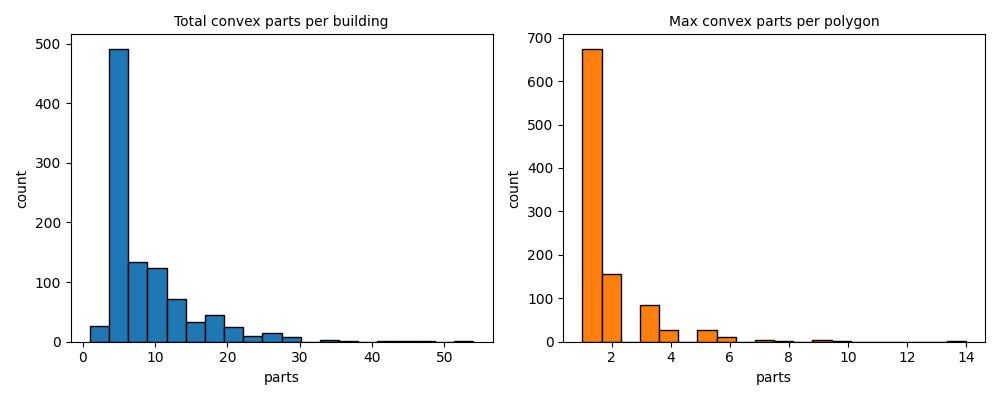

In [12]:
total_parts = buildings_convex_gdf['convex_parts_counts'].apply(lambda xs: int(sum(xs)) if isinstance(xs, list) else 0)
max_parts = buildings_convex_gdf['convex_parts_counts'].apply(lambda xs: int(max(xs)) if isinstance(xs, list) and xs else 0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(total_parts, bins=20, color='#1f77b4', edgecolor='black')
axes[0].set_title('Total convex parts per building')
axes[0].set_xlabel('parts')
axes[0].set_ylabel('count')

axes[1].hist(max_parts, bins=20, color='#ff7f0e', edgecolor='black')
axes[1].set_title('Max convex parts per polygon')
axes[1].set_xlabel('parts')
axes[1].set_ylabel('count')

plt.tight_layout()
plt.show()


### Plot vertex-binned success and runtime


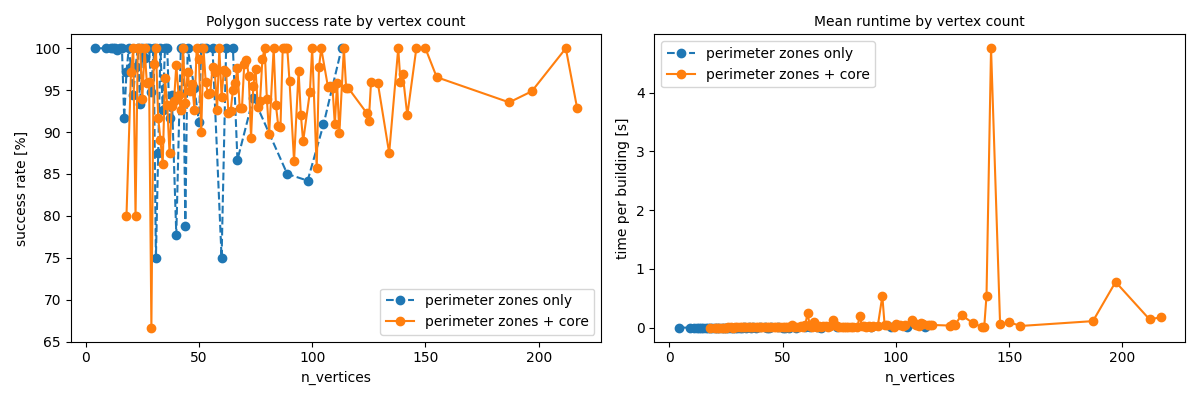

In [13]:
stats_plot_df = buildings_convex_gdf.copy()
stats_plot_df['perimeter_bool'] = stats_plot_df['perimeter'].fillna(False).astype(bool)
stats_plot_df['polygon_success_rate'] = stats_plot_df['polygon_fully_convex_flags'].apply(
    lambda flags: (sum(flags) / len(flags)) if isinstance(flags, list) and flags else np.nan
)

grouped = (
    stats_plot_df
    .groupby(['n_vertices', 'perimeter_bool'])[['polygon_success_rate', 'time_total_seconds']]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

for is_perimeter, linestyle, label in [(False, '--', 'perimeter zones only'), (True, '-', 'perimeter zones + core')]:
    sub = grouped.loc[grouped['perimeter_bool'] == is_perimeter].sort_values('n_vertices')
    if sub.empty:
        continue
    axes[0].plot(sub['n_vertices'], 100.0 * sub['polygon_success_rate'], linestyle=linestyle, marker='o', label=label)
    axes[1].plot(sub['n_vertices'], sub['time_total_seconds'], linestyle=linestyle, marker='o', label=label)

axes[0].set_title('Polygon success rate by vertex count')
axes[0].set_xlabel('n_vertices')
axes[0].set_ylabel('success rate [%]')
axes[0].legend()

axes[1].set_title('Mean runtime by vertex count')
axes[1].set_xlabel('n_vertices')
axes[1].set_ylabel('time per building [s]')
axes[1].legend()

plt.tight_layout()
plt.show()


### Plot original versus convex comparison grids

**Inputs**
- `buildings_convex_gdf` with the convex decomposition results of buildings with and without a core
- `select_complexity_ids`, `parts_from_geom`, and `GHSL_gridplot`

**Steps**
1. Select representative buildings with perimeter zones only and with perimeter zones and a core, across the vertex range.
2. Build ordered GeoDataFrame views for original outlines and convex-part overlays.
3. Plot four comparison grids: original and convex parts of the buildings without a core, perimeter band and core and convex parts of those with a core.
4. Save each rendered grid as a PDF under `tmp/osm_2_decomposition_exports/`.

**Outputs**
- Four displayed comparison grids
- PDF exports in `tmp/osm_2_decomposition_exports/`


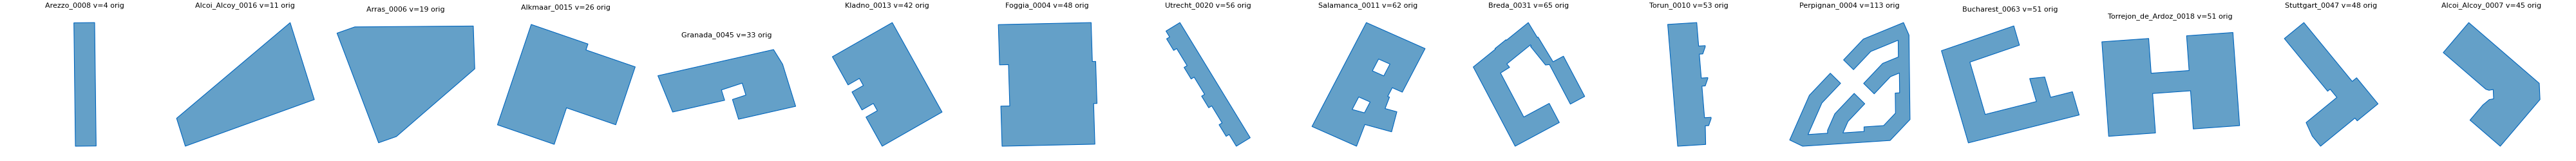

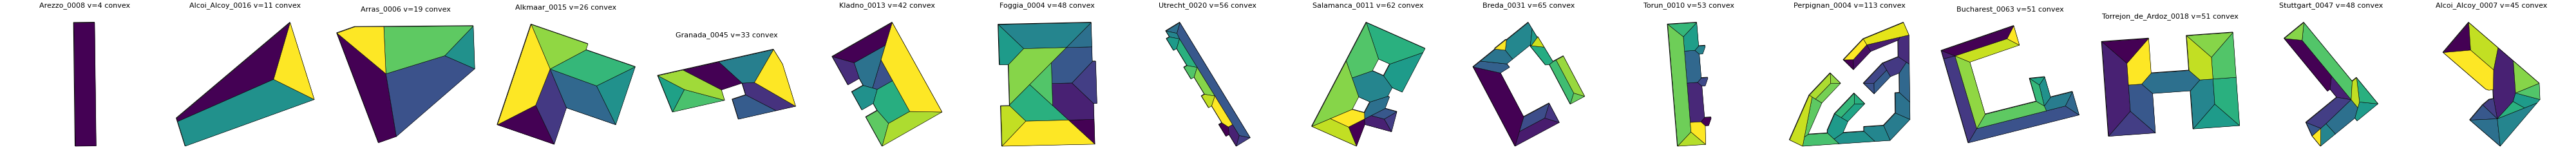

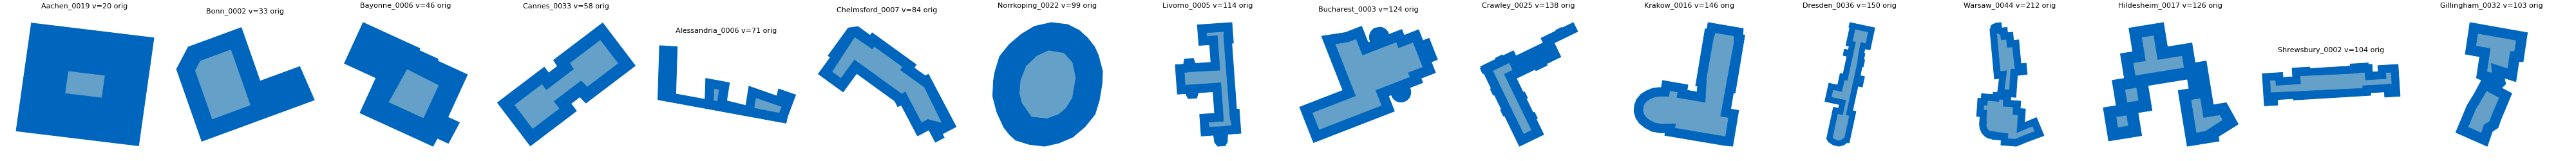

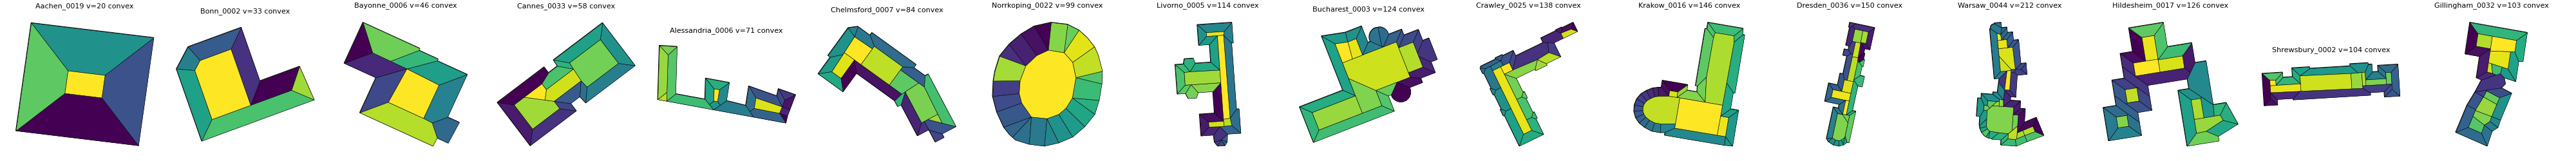

In [14]:
TUM_DARK = '#0065BD'
TUM_LIGHT = '#64A0C8'
N_COMPARE = 16
EXPORT_DIR = PROJECT_ROOT / 'tmp' / 'osm_2_decomposition_exports'
EXPORT_DIR.mkdir(parents=True, exist_ok=True)


def save_current_grid_pdf(stem: str) -> None:
    fig = plt.gcf()
    fig.savefig(EXPORT_DIR / f'{stem}.pdf', bbox_inches='tight')


nonperim_ids = select_complexity_ids(buildings_convex_gdf, perimeter_flag=False, n_examples=N_COMPARE)
perim_ids_compare = select_complexity_ids(buildings_convex_gdf, perimeter_flag=True, n_examples=N_COMPARE)

nonperim = buildings_convex_gdf.loc[buildings_convex_gdf['sample_id'].isin(nonperim_ids)].copy()
nonperim['sample_id'] = nonperim['sample_id'].astype(str)
nonperim['order_idx'] = nonperim['sample_id'].map({sid: i for i, sid in enumerate(nonperim_ids)})
nonperim = nonperim.sort_values('order_idx')
nonperim_outline = gpd.GeoDataFrame(nonperim, geometry='geometry', crs=buildings_convex_gdf.crs)
nonperim_parts = nonperim.copy()
nonperim_parts['convex_parts_list'] = nonperim_parts['convex_parts_geom'].apply(parts_from_geom)
nonperim_lookup = nonperim.set_index('sample_id')

if nonperim_ids:
    GHSL_gridplot(
        [
            {
                'name': 'nonperim_original',
                'gdf': nonperim_outline,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'geometry',
                'color': TUM_LIGHT,
                'edgecolor': TUM_DARK,
                'linewidth': 0.8,
            }
        ],
        ids=nonperim_ids,
        ncols=len(nonperim_ids),
        nrows=1,
        figsize_scale=2.5,
        title_fn=lambda sid, i: f"{sid} v={int(nonperim_lookup.loc[sid, 'n_vertices'])} orig",
    )
    save_current_grid_pdf('nonperim_original_grid')
    plt.show()

    GHSL_gridplot(
        [
            {
                'name': 'nonperim_outline',
                'gdf': nonperim_outline,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'geometry',
                'color': 'none',
                'edgecolor': 'black',
                'linewidth': 0.8,
            },
            {
                'name': 'nonperim_convex_parts',
                'gdf': nonperim_parts,
                'role': 'main',
                'id_col': 'sample_id',
                'parts_col': 'convex_parts_list',
                'cmap': 'viridis',
                'edgecolor': 'black',
                'linewidth': 0.4,
            },
        ],
        ids=nonperim_ids,
        ncols=len(nonperim_ids),
        nrows=1,
        figsize_scale=2.5,
        title_fn=lambda sid, i: f"{sid} v={int(nonperim_lookup.loc[sid, 'n_vertices'])} convex",
    )
    save_current_grid_pdf('nonperim_convex_grid')
    plt.show()

perim = buildings_convex_gdf.loc[buildings_convex_gdf['sample_id'].isin(perim_ids_compare)].copy()
perim['sample_id'] = perim['sample_id'].astype(str)
perim['order_idx'] = perim['sample_id'].map({sid: i for i, sid in enumerate(perim_ids_compare)})
perim = perim.sort_values('order_idx')
perim_shell = gpd.GeoDataFrame(perim, geometry='perimeter_geom', crs=buildings_convex_gdf.crs)
perim_interior = gpd.GeoDataFrame(perim.loc[perim['interior_geom'].notna()].copy(), geometry='interior_geom', crs=buildings_convex_gdf.crs)
perim_parts = perim.copy()
perim_parts['convex_parts_list'] = perim_parts['convex_parts_geom'].apply(parts_from_geom)
perim_lookup = perim.set_index('sample_id')

if perim_ids_compare:
    GHSL_gridplot(
        [
            {
                'name': 'perim_shell',
                'gdf': perim_shell,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'perimeter_geom',
                'color': TUM_DARK,
                'edgecolor': TUM_DARK,
                'linewidth': 0.8,
            },
            {
                'name': 'perim_interior',
                'gdf': perim_interior,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'interior_geom',
                'color': TUM_LIGHT,
                'edgecolor': TUM_DARK,
                'linewidth': 0.5,
            },
        ],
        ids=perim_ids_compare,
        ncols=len(perim_ids_compare),
        nrows=1,
        figsize_scale=2.5,
        title_fn=lambda sid, i: f"{sid} v={int(perim_lookup.loc[sid, 'n_vertices'])} orig",
    )
    save_current_grid_pdf('perim_original_grid')
    plt.show()

    GHSL_gridplot(
        [
            {
                'name': 'perim_outline',
                'gdf': perim_shell,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'perimeter_geom',
                'color': 'none',
                'edgecolor': 'black',
                'linewidth': 0.8,
            },
            {
                'name': 'perim_convex_parts',
                'gdf': perim_parts,
                'role': 'main',
                'id_col': 'sample_id',
                'parts_col': 'convex_parts_list',
                'cmap': 'viridis',
                'edgecolor': 'black',
                'linewidth': 0.4,
            },
        ],
        ids=perim_ids_compare,
        ncols=len(perim_ids_compare),
        nrows=1,
        figsize_scale=2.5,
        title_fn=lambda sid, i: f"{sid} v={int(perim_lookup.loc[sid, 'n_vertices'])} convex",
    )
    save_current_grid_pdf('perim_convex_grid')
    plt.show()


## Final pipeline summary

### Summarize convex coverage for the OSM working set

Report the final building-level counts from the current OSM decomposition run:
1. Buildings with at least one failed polygon decomposition.
2. Buildings whose decomposed output is fully convex.
3. Buildings whose decomposed output is fully convex and all zones are at least `cfg.min_area_m2`.
4. The retained building table `buildings_convex_gdf`, which keeps the full working set and adds decomposition diagnostics.

In [15]:
n_loaded = len(subset_buildings_gdf)
n_total = len(buildings_convex_gdf)

fully_convex_flags = buildings_convex_gdf['building_fully_convex'].fillna(False).astype(bool).to_numpy(dtype=bool)
failed_flags = buildings_convex_gdf['building_decomposition_failed'].fillna(False).astype(bool).to_numpy(dtype=bool)
small_zone_flags = buildings_convex_gdf['building_has_small_zone'].fillna(False).astype(bool).to_numpy(dtype=bool)
clean_convex_flags = fully_convex_flags & ~small_zone_flags

n_failed = int(np.sum(failed_flags))
n_fully_convex = int(np.sum(fully_convex_flags))
n_clean_convex = int(np.sum(clean_convex_flags))
n_small_zone = int(np.sum(small_zone_flags))

pct_failed = 100.0 * n_failed / n_total if n_total else 0.0
pct_fully_convex = 100.0 * n_fully_convex / n_total if n_total else 0.0
pct_clean_convex = 100.0 * n_clean_convex / n_total if n_total else 0.0
pct_small_zone = 100.0 * n_small_zone / n_total if n_total else 0.0
pct_retained = 100.0 * n_total / n_loaded if n_loaded else 0.0

print('=== Dataset-level pipeline summary ===')
print(f'Loaded preselected subset: {n_loaded}')
print(f'Buildings prepared for decomposition: {n_total} / {n_loaded} ({pct_retained:.1f}%)')
print(f'Buildings with at least one failed polygon decomposition: {n_failed} / {n_total} ({pct_failed:.1f}%)')
print(f'Fully convex after H/V decomposition: {n_fully_convex} / {n_total} ({pct_fully_convex:.1f}%)')
print(
    f'Fully convex and all zones >= {cfg.min_area_m2:.1f} m^2 after decomposition: '
    f'{n_clean_convex} / {n_total} ({pct_clean_convex:.1f}%)'
)
print(f'Buildings with any zone smaller than {cfg.min_area_m2:.1f} m^2: {n_small_zone} / {n_total} ({pct_small_zone:.1f}%)')
print(
    'Retained building table with decomposition diagnostics '
    f'(no extra post-decomposition geometry filter): {n_total} / {n_loaded} ({pct_retained:.1f}%)'
)


=== Dataset-level pipeline summary ===
Loaded preselected subset: 990
Buildings prepared for decomposition: 990 / 990 (100.0%)
Buildings with at least one failed polygon decomposition: 236 / 990 (23.8%)
Fully convex after H/V decomposition: 754 / 990 (76.2%)
Fully convex and all zones >= 2.0 m^2 after decomposition: 754 / 990 (76.2%)
Buildings with any zone smaller than 2.0 m^2: 0 / 990 (0.0%)
Retained building table with decomposition diagnostics (no extra post-decomposition geometry filter): 990 / 990 (100.0%)


## Export zone provenance and boundary interfaces

The convex parts alone cannot say which of their walls exist in reality. This section records, for every part, which building and which prepared zone it came from, and classifies every boundary sub-segment it owns.

An OSM footprint is a single physical envelope, so the whole building is one space and the perimeter zones, thin zones, and core parts are zones inside it. A cut between two of those pieces is therefore reported as `zoning_split`, a deliberate thermal-zoning boundary, while a cut produced by the convex decomposition inside one piece is reported as `artificial_split`. Both are virtual, but only the second one is an artifact of the decomposition.

**Inputs**
- `polygon_results_gdf` with one row per prepared zone, its source polygon, and its convex parts
- `OSM_DATA_DIR` as the output location

**Steps**
1. Build one part record per convex part with its `container -> space -> zone -> part` chain.
2. Classify every boundary sub-segment against the neighbouring parts of the same building.
3. Report the aggregate counts, including unmatched segments that indicate an imperfect tiling.
4. Write the `zones` and `interfaces` layers to `osm_zones.gpkg` in `OSM_DATA_DIR`.

**Outputs**
- `osm_parts`, `osm_interfaces`, `osm_zone_summary`
- `osm_zones.gpkg` in `OSM_DATA_DIR`

**Used functions**
`osm_part_records`, `build_interfaces`, `summarize_interfaces`, `parts_to_geodataframe`, `interfaces_to_geodataframe`, `write_zone_artifacts`


In [16]:
from convexdecomp.zones.adapters import osm_part_records
from convexdecomp.zones.export import (
    interfaces_to_geodataframe,
    parts_to_geodataframe,
    write_zone_artifacts,
)
from convexdecomp.zones.interfaces import (
    InterfaceConfig,
    build_interfaces,
    summarize_interfaces,
)

ZONE_INTERFACE_CFG = InterfaceConfig(tol=1e-6)

osm_parts = osm_part_records(polygon_results_gdf)
osm_interfaces = build_interfaces(osm_parts, ZONE_INTERFACE_CFG)
osm_zone_summary = summarize_interfaces(osm_parts, osm_interfaces)

print('=== OSM zone provenance ===')
print(f"Convex parts: {osm_zone_summary['n_parts']}")
print(f"Source spaces (buildings): {osm_zone_summary['n_spaces']}")
print(f"Spaces split into several parts: {osm_zone_summary['n_split_spaces']}")
print(f"Boundary segments: {osm_zone_summary['n_interfaces']}")
print(f"Virtual segments (artificial + zoning): {osm_zone_summary['n_virtual_interfaces']}")
print(f"Unmatched segments: {osm_zone_summary['n_unmatched']}")
print(f"Ambiguous segments: {osm_zone_summary['n_ambiguous']}")
print('')
print('Boundary length by kind [m]:')
for kind, length in sorted(osm_zone_summary['interface_length_by_kind'].items()):
    print(f'  {kind:20s} {length:12.2f}')

if osm_zone_summary['n_unmatched']:
    unmatched_length = osm_zone_summary['interface_length_by_kind'].get('unmatched', 0.0)
    total_length = sum(osm_zone_summary['interface_length_by_kind'].values())
    print('')
    print(
        f"Note: {osm_zone_summary['n_unmatched']} segments ({100.0 * unmatched_length / total_length:.2f}% of "
        'boundary length) have no neighbouring part and do not lie on their source zone boundary. '
        'They mark places where the decomposed parts do not tile their source zone exactly. '
        'Raise ZONE_INTERFACE_CFG.tol if they are numerical, or inspect them as geometry defects.'
    )

osm_zones_gdf = parts_to_geodataframe(osm_parts, crs=buildings_convex_gdf.crs)
osm_interfaces_gdf = interfaces_to_geodataframe(osm_interfaces, crs=buildings_convex_gdf.crs)

osm_zone_paths = write_zone_artifacts(
    osm_zones_gdf,
    osm_interfaces_gdf,
    OSM_DATA_DIR / 'osm_zones.gpkg',
)
print('')
for layer, path in osm_zone_paths.items():
    print(f'Wrote layer {layer} to {Path(path).resolve().relative_to(PROJECT_ROOT)}')


=== OSM zone provenance ===
Convex parts: 8853
Source spaces (buildings): 990
Spaces split into several parts: 988
Boundary segments: 39243
Virtual segments (artificial + zoning): 29366
Unmatched segments: 0
Ambiguous segments: 0

Boundary length by kind [m]:
  artificial_split          8803.43
  exterior                 95300.90
  zoning_split            184363.91



Wrote layer zones to data/bem4ai/osm_zones.gpkg
Wrote layer interfaces to data/bem4ai/osm_zones.gpkg
